In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
import warnings

warnings.filterwarnings("ignore")

# Your five CSV files are uploaded directly to Colab
DATA_DIR = Path("/content")

required_files = {
    "students": "students.csv",
    "attendance": "attendance.csv",
    "assessments": "assessments.csv",
    "engagement": "engagement.csv",
    "courses": "courses.csv"
}

datasets = {}

for name, filename in required_files.items():
    file_path = DATA_DIR / filename

    if not file_path.exists():
        raise FileNotFoundError(
            f"{filename} not found in /content. "
            "Check the uploaded filename."
        )

    datasets[name] = pd.read_csv(file_path)

    print(
        f"{name.upper()}: "
        f"{datasets[name].shape[0]} rows × "
        f"{datasets[name].shape[1]} columns"
    )

print("\nAll five datasets loaded successfully.")

STUDENTS: 120 rows × 4 columns
ATTENDANCE: 578 rows × 4 columns
ASSESSMENTS: 578 rows × 6 columns
ENGAGEMENT: 577 rows × 5 columns
COURSES: 8 rows × 4 columns

All five datasets loaded successfully.


In [2]:
for name, df in datasets.items():
    print(f"\n{'='*50}")
    print(name.upper())
    display(df.head())


STUDENTS


,student_id,programme,semester,demographic_group
0,STU001,B.Tech IT,5,Group C
1,STU002,B.E. ECE,5,Group B
2,STU003,B.E. EEE,3,Group A
3,STU004,B.Tech IT,4,Group B
4,STU005,B.E. CSE,3,Group B



ATTENDANCE


,student_id,course_code,sessions_held,sessions_attended
0,STU001,CS301,27,20
1,STU001,IT307,35,16
2,STU001,MA305,24,17
3,STU001,EC304,36,14
4,STU001,EE308,24,13



ASSESSMENTS


,student_id,course_code,quiz,assignment,test,lab
0,STU001,CS301,61.3,66.2,44.4,64.2
1,STU001,IT307,74.5,54.3,43.2,65.5
2,STU001,MA305,88.0,63.0,30.0,81.5
3,STU001,EC304,31.8,48.1,125.0,62.8
4,STU001,EE308,68.0,66.0,68.3,68.7



ENGAGEMENT


,student_id,course_code,lms_logins,submissions,activity
0,STU001,CS301,17.0,9,60.0
1,STU001,IT307,20.0,8,68.0
2,STU001,MA305,15.0,9,59.0
3,STU001,EC304,17.0,6,30.0
4,STU001,EE308,19.0,7,53.0



COURSES


,course_code,course_type,credits,faculty
0,CS301,Core,4,Faculty A
1,CS302,Core,3,Faculty B
2,IT303,Core,4,Faculty C
3,EC304,Core,3,Faculty D
4,MA305,Foundation,4,Faculty E


In [3]:
for name, df in datasets.items():
    print(f"\n--- {name.upper()} ---")
    print("Shape:", df.shape)
    print("\nColumn names:")
    print(df.columns.tolist())
    print("\nData types:")
    print(df.dtypes)


--- STUDENTS ---
Shape: (120, 4)

Column names:
['student_id', 'programme', 'semester', 'demographic_group']

Data types:
student_id           object
programme            object
semester              int64
demographic_group    object
dtype: object

--- ATTENDANCE ---
Shape: (578, 4)

Column names:
['student_id', 'course_code', 'sessions_held', 'sessions_attended']

Data types:
student_id           object
course_code          object
sessions_held         int64
sessions_attended     int64
dtype: object

--- ASSESSMENTS ---
Shape: (578, 6)

Column names:
['student_id', 'course_code', 'quiz', 'assignment', 'test', 'lab']

Data types:
student_id      object
course_code     object
quiz           float64
assignment     float64
test           float64
lab            float64
dtype: object

--- ENGAGEMENT ---
Shape: (577, 5)

Column names:
['student_id', 'course_code', 'lms_logins', 'submissions', 'activity']

Data types:
student_id      object
course_code     object
lms_logins     float64
submi

In [4]:
for name, df in datasets.items():
    print(f"\n--- {name.upper()} ---")

    print("Missing values:")
    display(df.isnull().sum().to_frame("Missing Count"))

    print("Duplicate rows:", df.duplicated().sum())


--- STUDENTS ---
Missing values:


,Missing Count
student_id,0
programme,0
semester,0
demographic_group,0


Duplicate rows: 0

--- ATTENDANCE ---
Missing values:


,Missing Count
student_id,0
course_code,0
sessions_held,0
sessions_attended,0


Duplicate rows: 1

--- ASSESSMENTS ---
Missing values:


...

Duplicate rows: 1

--- ENGAGEMENT ---
Missing values:


,Missing Count
student_id,0
course_code,0
lms_logins,10
submissions,0
activity,10


Duplicate rows: 0

--- COURSES ---
Missing values:


,Missing Count
course_code,0
course_type,0
credits,0
faculty,0


Duplicate rows: 0


In [5]:
for name, df in datasets.items():
    print(f"\n--- {name.upper()} ---")

    numeric_cols = df.select_dtypes(include=np.number).columns

    if len(numeric_cols) > 0:
        display(df[numeric_cols].describe().T)
    else:
        print("No numerical columns found.")


--- STUDENTS ---


,count,mean,std,min,25%,50%,75%,max
semester,120.0,4.441667,1.090801,3.0,3.0,4.0,5.0,6.0



--- ATTENDANCE ---


,count,mean,std,min,25%,50%,75%,max
sessions_held,578.0,32.027682,4.867670,24.0,28.0,32.0,36.0,40.0
sessions_attended,578.0,19.628028,5.214801,6.0,16.0,19.0,23.0,37.0



--- ASSESSMENTS ---


,count,mean,std,min,25%,50%,75%,max
quiz,564.0,64.180319,19.112183,-5.0,50.975,64.70,76.825,100.0
assignment,564.0,68.481560,16.637137,11.1,57.000,69.30,80.325,100.0
test,564.0,62.307092,19.641076,0.9,49.200,62.35,75.200,125.0
lab,564.0,70.102482,15.999407,29.2,58.775,69.60,82.125,108.0



--- ENGAGEMENT ---


,count,mean,std,min,25%,50%,75%,max
lms_logins,567.0,16.978836,5.496183,0.0,14.0,17.0,20.0,34.0
submissions,577.0,8.769497,2.234648,3.0,7.0,9.0,10.0,15.0
activity,567.0,50.758377,13.634159,2.0,42.0,52.0,59.0,98.0



--- COURSES ---


,count,mean,std,min,25%,50%,75%,max
credits,8.0,3.25,0.707107,2.0,3.0,3.0,4.0,4.0


In [6]:
cleaned = {}

for name, df in datasets.items():
    df = df.copy()

    # Standardize column names
    df.columns = (
        df.columns.str.strip()
        .str.lower()
        .str.replace(" ", "_", regex=False)
    )

    # Remove exact duplicate rows
    before = len(df)
    df = df.drop_duplicates().copy()
    removed = before - len(df)

    cleaned[name] = df

    print(
        f"{name.upper()}: removed {removed} exact duplicate rows; "
        f"{len(df)} rows remain."
    )

datasets = cleaned

STUDENTS: removed 0 exact duplicate rows; 120 rows remain.
ATTENDANCE: removed 1 exact duplicate rows; 577 rows remain.
ASSESSMENTS: removed 1 exact duplicate rows; 577 rows remain.
ENGAGEMENT: removed 0 exact duplicate rows; 577 rows remain.
COURSES: removed 0 exact duplicate rows; 8 rows remain.


In [7]:
for name in ["attendance", "assessments", "engagement", "courses"]:
    datasets[name]["course_code"] = (
        datasets[name]["course_code"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

print("Course codes standardized.")

Course codes standardized.


In [8]:
attendance = datasets["attendance"].copy()

attendance["attendance_percentage"] = np.where(
    attendance["sessions_held"] > 0,
    attendance["sessions_attended"]
    / attendance["sessions_held"] * 100,
    np.nan
)

attendance["attendance_valid"] = (
    (attendance["sessions_held"] >= 0)
    & (attendance["sessions_attended"] >= 0)
    & (attendance["sessions_attended"] <= attendance["sessions_held"])
)

print("Invalid attendance records:", (~attendance["attendance_valid"]).sum())
display(attendance.head())

Invalid attendance records: 0


,student_id,course_code,sessions_held,sessions_attended,attendance_percentage,attendance_valid
0,STU001,CS301,27,20,74.074074,True
1,STU001,IT307,35,16,45.714286,True
2,STU001,MA305,24,17,70.833333,True
3,STU001,EC304,36,14,38.888889,True
4,STU001,EE308,24,13,54.166667,True


In [9]:
assessments = datasets["assessments"].copy()

score_cols = ["quiz", "assignment", "test", "lab"]

for col in score_cols:
    assessments[col] = pd.to_numeric(
        assessments[col], errors="coerce"
    )

    invalid = (assessments[col] < 0) | (assessments[col] > 100)

    print(f"{col}: invalid scores = {invalid.sum()}")

    assessments.loc[invalid, col] = np.nan

display(assessments.head())

quiz: invalid scores = 1
assignment: invalid scores = 0
test: invalid scores = 1
lab: invalid scores = 1


,student_id,course_code,quiz,assignment,test,lab
0,STU001,CS301,61.3,66.2,44.4,64.2
1,STU001,IT307,74.5,54.3,43.2,65.5
2,STU001,MA305,88.0,63.0,30.0,81.5
3,STU001,EC304,31.8,48.1,NaN,62.8
4,STU001,EE308,68.0,66.0,68.3,68.7


In [10]:
assessments["average_assessment_score"] = (
    assessments[score_cols].mean(axis=1)
)

display(assessments.head())

,student_id,course_code,quiz,assignment,test,lab,average_assessment_score
0,STU001,CS301,61.3,66.2,44.4,64.2,59.025000
1,STU001,IT307,74.5,54.3,43.2,65.5,59.375000
2,STU001,MA305,88.0,63.0,30.0,81.5,65.625000
3,STU001,EC304,31.8,48.1,NaN,62.8,47.566667
4,STU001,EE308,68.0,66.0,68.3,68.7,67.750000


In [11]:
students = datasets["students"].copy()
engagement = datasets["engagement"].copy()
courses = datasets["courses"].copy()

student_course = attendance.merge(
    assessments,
    on=["student_id", "course_code"],
    how="outer",
    suffixes=("_attendance", "_assessment")
)

student_course = student_course.merge(
    students,
    on="student_id",
    how="left"
)

student_course = student_course.merge(
    engagement,
    on=["student_id", "course_code"],
    how="left",
    suffixes=("", "_engagement")
)

student_course = student_course.merge(
    courses,
    on="course_code",
    how="left",
    validate="many_to_one"
)

print("Combined dataset shape:", student_course.shape)
print("Columns:", student_course.columns.tolist())
display(student_course.head())

Combined dataset shape: (578, 20)
Columns: ['student_id', 'course_code', 'sessions_held', 'sessions_attended', 'attendance_percentage', 'attendance_valid', 'quiz', 'assignment', 'test', 'lab', 'average_assessment_score', 'programme', 'semester', 'demographic_group', 'lms_logins', 'submissions', 'activity', 'course_type', 'credits', 'faculty']


,student_id,course_code,sessions_held,sessions_attended,attendance_percentage,attendance_valid,quiz,assignment,test,lab,average_assessment_score,programme,semester,demographic_group,lms_logins,submissions,activity,course_type,credits,faculty
0,STU001,CS301,27,20,74.074074,True,61.3,66.2,44.4,64.2,59.025000,B.Tech IT,5,Group C,17.0,9.0,60.0,Core,4,Faculty A
1,STU001,CS306,38,24,63.157895,True,56.7,71.6,55.7,67.4,62.850000,B.Tech IT,5,Group C,21.0,4.0,46.0,Practical,2,Faculty A
2,STU001,EC304,36,14,38.888889,True,31.8,48.1,NaN,62.8,47.566667,B.Tech IT,5,Group C,17.0,6.0,30.0,Core,3,Faculty D
3,STU001,EE308,24,13,54.166667,True,68.0,66.0,68.3,68.7,67.750000,B.Tech IT,5,Group C,19.0,7.0,53.0,Core,3,Faculty G
4,STU001,IT307,35,16,45.714286,True,74.5,54.3,43.2,65.5,59.375000,B.Tech IT,5,Group C,20.0,8.0,68.0,Elective,3,Faculty F


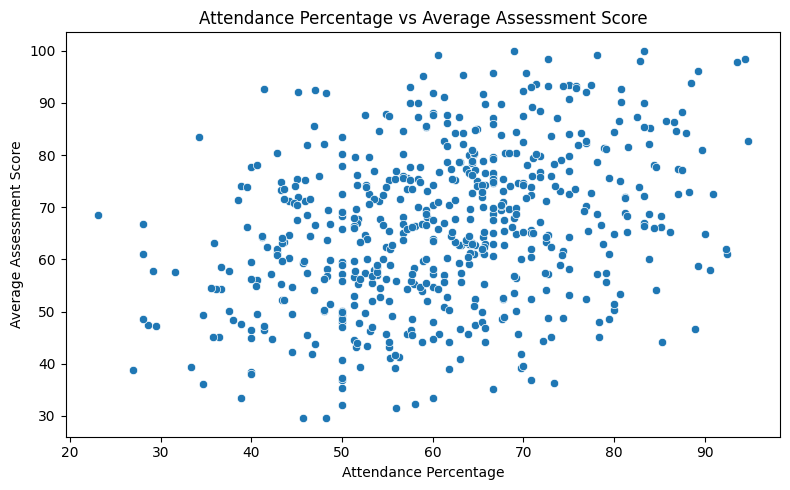

Correlation: 0.337700842935167


In [12]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=student_course,
    x="attendance_percentage",
    y="average_assessment_score"
)

plt.title("Attendance Percentage vs Average Assessment Score")
plt.xlabel("Attendance Percentage")
plt.ylabel("Average Assessment Score")
plt.tight_layout()
plt.show()

print(
    "Correlation:",
    student_course[
        ["attendance_percentage", "average_assessment_score"]
    ].corr().iloc[0, 1]
)

,Average Score
course_code,
CS301,68.750803
IT303,67.528261
EC304,67.109662
EE308,66.578690
IT307,65.099087
MA305,65.013718
CS306,64.777111
CS302,64.644178


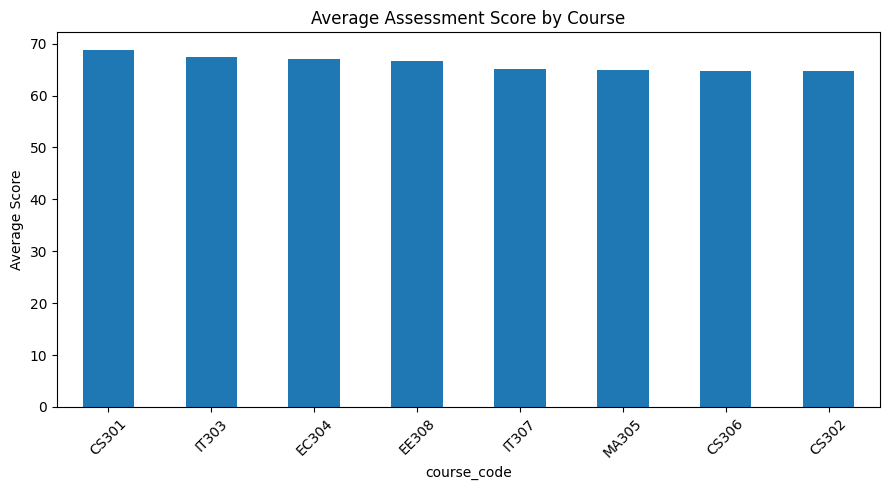

In [13]:
course_performance = (
    student_course.groupby("course_code")["average_assessment_score"]
    .mean()
    .sort_values(ascending=False)
)

display(course_performance.to_frame("Average Score"))

course_performance.plot(
    kind="bar",
    figsize=(9, 5),
    title="Average Assessment Score by Course",
    ylabel="Average Score"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,quiz,assignment,test,lab
mean,64.239680,68.425577,62.134875,69.981851
median,64.700000,69.200000,62.200000,69.450000
std,18.861498,16.598677,19.443238,15.897345
min,7.200000,11.100000,0.900000,29.200000
max,100.000000,100.000000,100.000000,100.000000


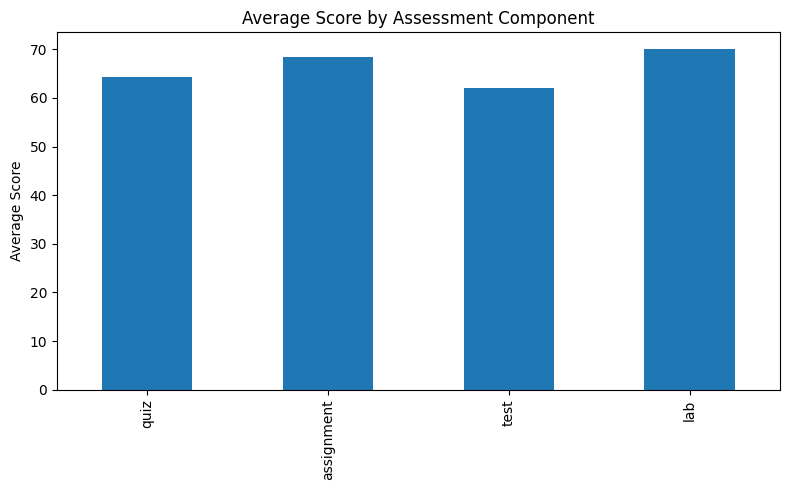

In [14]:
assessment_summary = student_course[score_cols].agg(
    ["mean", "median", "std", "min", "max"]
)

display(assessment_summary)

student_course[score_cols].mean().plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Score by Assessment Component",
    ylabel="Average Score"
)

plt.tight_layout()
plt.show()

,count,mean,std,min,25%,50%,75%,max
lms_logins,567.0,16.987654,5.498621,0.0,14.0,17.0,20.0,34.0
submissions,577.0,8.778163,2.241343,3.0,7.0,9.0,10.0,15.0
activity,567.0,50.760141,13.633607,2.0,42.0,52.0,59.0,98.0


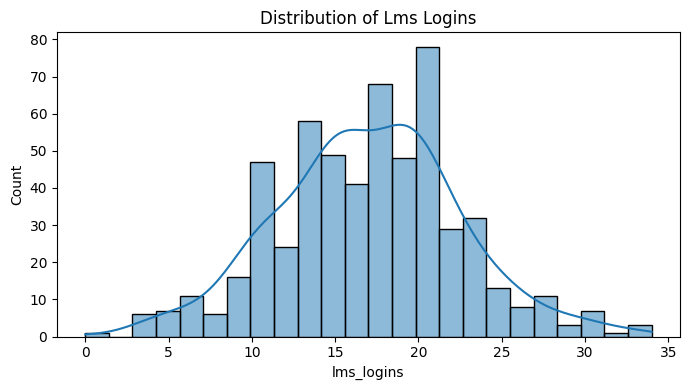

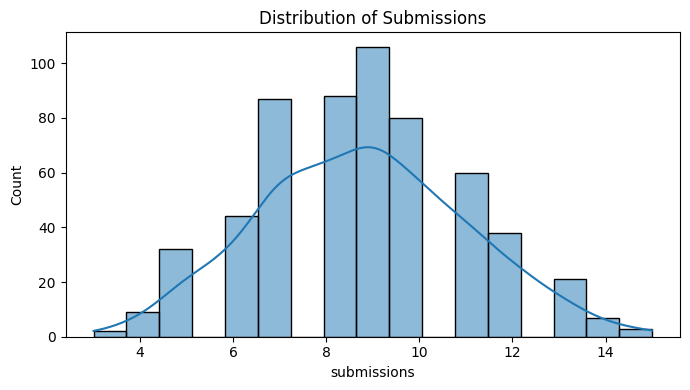

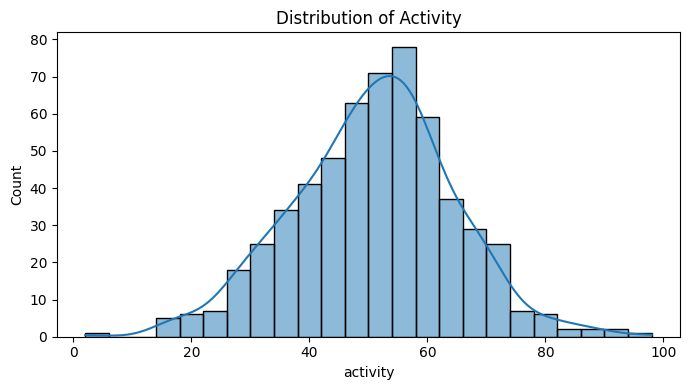

In [15]:
engagement_cols = [
    "lms_logins",
    "submissions",
    "activity"
]

display(student_course[engagement_cols].describe().T)

for col in engagement_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=student_course, x=col, kde=True)
    plt.title(f"Distribution of {col.replace('_', ' ').title()}")
    plt.tight_layout()
    plt.show()

In [16]:
student_course["performance_group"] = pd.cut(
    student_course["average_assessment_score"],
    bins=[-0.01, 40, 60, 75, 100],
    labels=[
        "Needs Support",
        "Developing",
        "Good",
        "High Performance"
    ]
)

display(
    student_course["performance_group"]
    .value_counts(dropna=False)
    .to_frame("Record Count")
)

,Record Count
performance_group,
Good,213
Developing,175
High Performance,166
Needs Support,23
NaN,1


,lms_logins,submissions,activity
performance_group,,,
Needs Support,15.142857,7.363636,44.857143
Developing,15.695906,8.165714,48.830409
Good,17.033493,8.600939,50.942584
High Performance,18.484848,9.849398,53.224242


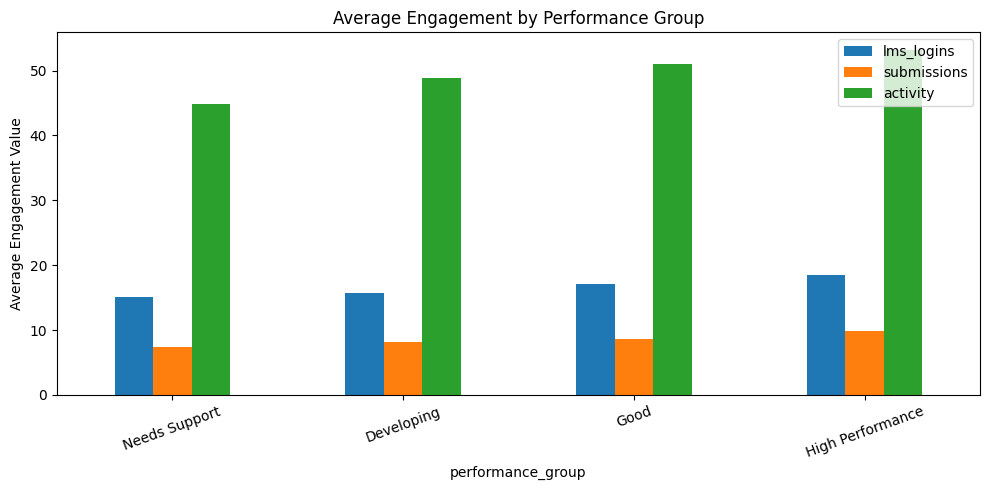

In [17]:
engagement_comparison = (
    student_course.groupby(
        "performance_group",
        observed=False
    )[engagement_cols]
    .mean()
)

display(engagement_comparison)

engagement_comparison.plot(
    kind="bar",
    figsize=(10, 5),
    title="Average Engagement by Performance Group",
    ylabel="Average Engagement Value"
)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

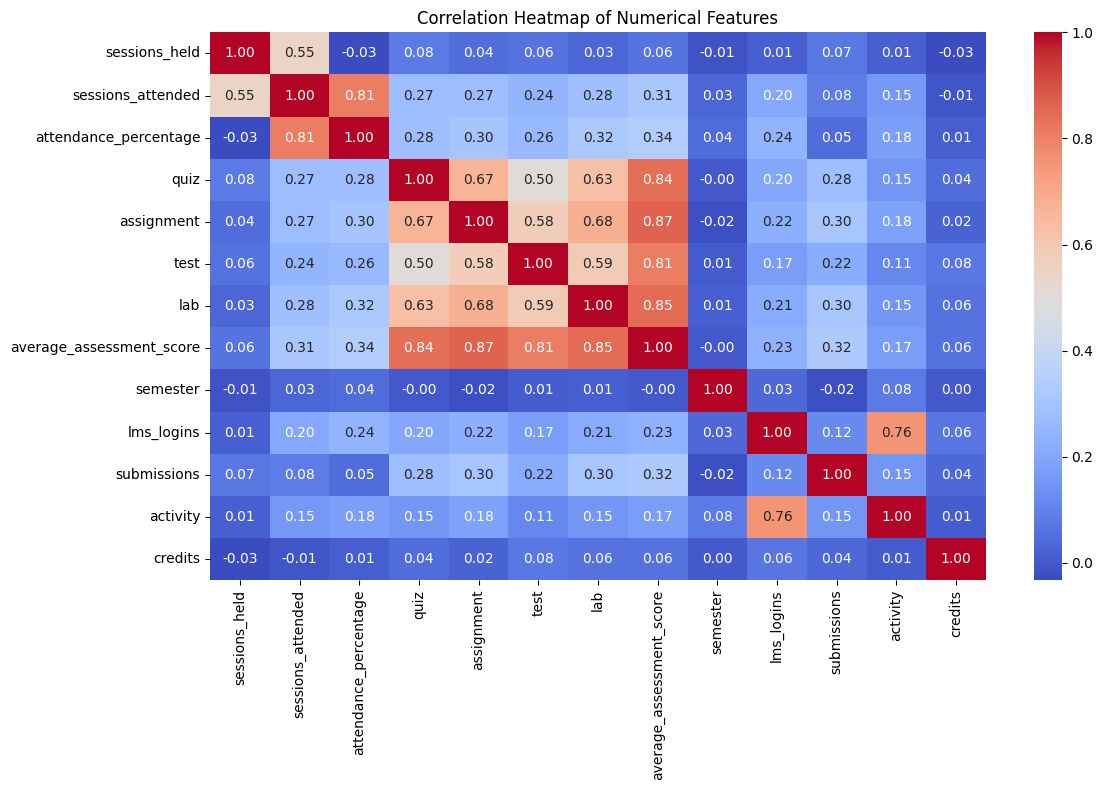

In [18]:
numeric_data = student_course.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [19]:
student_course["low_attendance_flag"] = (
    student_course["attendance_percentage"] < 75
).astype("Int64")

student_course["low_engagement_flag"] = (
    student_course["lms_logins"].fillna(0) < 5
).astype("Int64")

student_course["missing_assessment_count"] = (
    student_course[score_cols].isna().sum(axis=1)
)

student_course["total_submissions"] = student_course["submissions"]

display(
    student_course[
        [
            "student_id",
            "course_code",
            "attendance_percentage",
            "average_assessment_score",
            "low_attendance_flag",
            "low_engagement_flag",
            "missing_assessment_count"
        ]
    ].head(10)
)

,student_id,course_code,attendance_percentage,average_assessment_score,low_attendance_flag,low_engagement_flag,missing_assessment_count
0,STU001,CS301,74.074074,59.025000,1,0,0
1,STU001,CS306,63.157895,62.850000,1,0,0
2,STU001,EC304,38.888889,47.566667,1,0,1
3,STU001,EE308,54.166667,67.750000,1,0,0
4,STU001,IT307,45.714286,59.375000,1,0,0
5,STU001,MA305,70.833333,65.625000,1,0,0
6,STU002,CS301,46.666667,41.800000,1,0,0
7,STU002,CS302,51.351351,52.975000,1,0,0
8,STU002,CS306,50.000000,48.000000,1,0,0
9,STU002,MA305,69.230769,56.475000,1,0,0


In [20]:
student_course["support_priority"] = np.where(
    (student_course["average_assessment_score"] < 40)
    | (
        (student_course["attendance_percentage"] < 75)
        & (student_course["average_assessment_score"] < 60)
    ),
    "High Priority",
    "Regular Monitoring"
)

display(
    student_course["support_priority"]
    .value_counts()
    .to_frame("Record Count")
)

,Record Count
support_priority,
Regular Monitoring,397
High Priority,181


In [21]:
print("Missing values after merging:")
display(
    student_course.isnull()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing Count")
)

print("Exact duplicate rows:", student_course.duplicated().sum())

Missing values after merging:


,Missing Count
lab,16
test,16
quiz,16
assignment,15
lms_logins,11
activity,11
submissions,1
average_assessment_score,1
performance_group,1
total_submissions,1


Exact duplicate rows: 0


In [22]:
from pathlib import Path

output_dir = Path("/content/Student_Academic_Insight_Outputs")
output_dir.mkdir(parents=True, exist_ok=True)

student_course.to_csv(
    output_dir / "cleaned_student_course_data.csv",
    index=False
)

course_performance.to_csv(
    output_dir / "course_performance_summary.csv"
)

assessment_summary.to_csv(
    output_dir / "assessment_component_summary.csv"
)

engagement_comparison.to_csv(
    output_dir / "engagement_performance_summary.csv"
)

print("Files saved:")
for file in output_dir.iterdir():
    print(file.name)

Files saved:
engagement_performance_summary.csv
course_performance_summary.csv
cleaned_student_course_data.csv
assessment_component_summary.csv


In [23]:
from google.colab import files

files.download(
    "/content/Student_Academic_Insight_Outputs/cleaned_student_course_data.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/Student_Academic_Insight_Outputs",
    "zip",
    root_dir="/content/Student_Academic_Insight_Outputs"
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>